# PD05 · Particionamiento y comparación pandas–Polars

Continuación de PD01–PD03 basada en las clases del 9 y 10 de octubre de 2026. Tiempo orientativo: 210 minutos, con el entorno y los datos preparados.

Copia esta plantilla a `soluciones/` conservando su nombre. Escribe allí el código y las interpretaciones. Las celdas iniciales muestran las lecturas; las actividades quedan a tu cargo. Antes de entregar, reinicia el kernel y ejecuta todas las celdas en orden.

Utiliza directamente las API de pandas, Polars y GeoPandas. Mantén visibles las conversiones, máscaras, agrupaciones, uniones y exportaciones. No uses `talleres.py`, `pqrs_talleres.py`, comandos de shell ni funciones que resuelvan varias etapas sin mostrar su implementación. Un bucle de medición es válido si su cuerpo contiene las operaciones que estás midiendo. No instales paquetes desde el notebook.

[Índice](../ejercicios/README.md) · [Pandas](../docs/manual-pandas.md) · [Polars](../docs/manual-polars.md) · [GeoPandas](../docs/manual-geopandas.md)

## Ubicación de trabajo

Abre Jupyter desde la raíz del repositorio con el entorno del curso activo. Cambia `REPO` por la ruta real de tu copia. Las rutas son explícitas y funcionan tanto desde `ejercicios/` como desde `soluciones/`. Si falta un archivo, revisa su ubicación; no sustituyas silenciosamente la entrada por otro dataset.

## Pregunta y preparación

¿Cómo cambian lectura, escritura y procesamiento al variar formato, particionamiento y motor?

Requiere el Parquet completo y la capa municipal del GeoPackage de PD04 y las dependencias del entorno del curso: `requirements.txt` y `requirements_pqrs.txt`. Trabaja en CPU. No dupliques filas para simular volumen. Esta actividad estudia los resultados de este equipo y estos datos.

Las lecturas siguientes son directas. Para comparar CSV más adelante, escribe explícitamente `pd.read_csv` y `pl.read_csv`, sus separadores, política de nulos y tipos. No uses inferencia diferente de tipos como si fuera trabajo equivalente.

El particionamiento será manual: un `groupby` divide la tabla y cada grupo se escribe en un archivo independiente. Los valores de las claves permanecen dentro de cada archivo. Un inventario CSV registra dónde está cada parte; no se configura un catálogo ni un motor de particiones.


In [1]:
import os
import time
import platform
import pandas as pd
import polars as pl
import geopandas as gpd
import matplotlib.pyplot as plt
from pathlib import Path

REPO = "/opt/bigdata/big-data-postgraduate"
INPUT = REPO + "/kit/salidas/soluciones/PD04/analisis_integrados.parquet"
OUT = REPO + "/kit/salidas/soluciones/PD05"
os.makedirs(OUT, exist_ok=True)
print("Entrada:", INPUT)
print("Salidas:", OUT)
print(platform.platform())
print("pandas:", pd.__version__, "Polars:", pl.__version__, "GeoPandas:", gpd.__version__)

Entrada: /opt/bigdata/big-data-postgraduate/kit/salidas/soluciones/PD04/analisis_integrados.parquet
Salidas: /opt/bigdata/big-data-postgraduate/kit/salidas/soluciones/PD05
Linux-6.6.87.2-microsoft-standard-WSL2-x86_64-with-glibc2.43
pandas: 3.1.1 Polars: 1.35.2 GeoPandas: 1.2.0


In [2]:
datos_pd = pd.read_parquet(INPUT, engine="pyarrow")
display(datos_pd.head())
print(datos_pd.shape)
print(datos_pd.dtypes)

,id_fila,Secuencial,Fecha de Análisis,Departamento,Municipio,Cultivo,Estado,Tiempo de establecimiento,Topografia,Drenaje,...,codigo_municipio,nombre_departamento_divipola,nombre_municipio_divipola,longitud_territorial,latitud_territorial,estado_union,indicador_merge,estado_union_inicial,fuente_analisis,fuente_territorial
0,0,1,7/01/2014,NARIÑO,SAN ANDRÉS DE TUMACO,No Indica,No indica,No indica,No indica,No indica,...,52835,NARIÑO,SAN ANDRÉS DE TUMACO,-78.764073,1.807399,coincide,both,coincide,agrosavia.csv,divipola.csv (corte 2024)
1,1,2,21/08/2014,HUILA,SANTA MARÍA,Granadilla,Establecido,De 1 a 5 años,Pendiente,Buen drenaje,...,41676,HUILA,SANTA MARÍA,-75.586223,2.939603,coincide,both,coincide,agrosavia.csv,divipola.csv (corte 2024)
2,2,3,22/08/2014,ANTIOQUIA,LIBORINA,Café,Por establecer,No indica,Pendiente,Mal drenaje,...,05411,ANTIOQUIA,LIBORINA,-75.812838,6.677316,coincide,both,coincide,agrosavia.csv,divipola.csv (corte 2024)
3,3,4,22/08/2014,ANTIOQUIA,LIBORINA,Maracuyá,Por establecer,No indica,Ondulado,Mal drenaje,...,05411,ANTIOQUIA,LIBORINA,-75.812838,6.677316,coincide,both,coincide,agrosavia.csv,divipola.csv (corte 2024)
4,4,5,22/08/2014,ANTIOQUIA,LIBORINA,Café,Por establecer,No indica,Ondulado,Mal drenaje,...,05411,ANTIOQUIA,LIBORINA,-75.812838,6.677316,coincide,both,coincide,agrosavia.csv,divipola.csv (corte 2024)


(92738, 50)
id_fila                                        int64
Secuencial                                       str
Fecha de Análisis                                str
Departamento                                     str
Municipio                                        str
Cultivo                                          str
Estado                                           str
Tiempo de establecimiento                        str
Topografia                                       str
Drenaje                                          str
Riego                                            str
Fertilizantes aplicados                          str
pH agua:suelo                                    str
Materia organica                                 str
Fósforo Bray II                                  str
Azufre Fosfato monocalcico                       str
Acidez Intercambiable                            str
Aluminio intercambiable                          str
Calcio intercambiable             

In [3]:
datos_pl = pl.read_parquet(INPUT)
print(datos_pl.head())
print(datos_pl.shape)
print(datos_pl.schema)

shape: (5, 50)
┌─────────┬────────────┬───────────┬───────────┬───┬───────────┬───────────┬───────────┬───────────┐
│ id_fila ┆ Secuencial ┆ Fecha de  ┆ Departame ┆ … ┆ indicador ┆ estado_un ┆ fuente_an ┆ fuente_te │
│ ---     ┆ ---        ┆ Análisis  ┆ nto       ┆   ┆ _merge    ┆ ion_inici ┆ alisis    ┆ rritorial │
│ i64     ┆ str        ┆ ---       ┆ ---       ┆   ┆ ---       ┆ al        ┆ ---       ┆ ---       │
│         ┆            ┆ str       ┆ str       ┆   ┆ str       ┆ ---       ┆ str       ┆ str       │
│         ┆            ┆           ┆           ┆   ┆           ┆ str       ┆           ┆           │
╞═════════╪════════════╪═══════════╪═══════════╪═══╪═══════════╪═══════════╪═══════════╪═══════════╡
│ 0       ┆ 1          ┆ 7/01/2014 ┆ NARIÑO    ┆ … ┆ both      ┆ coincide  ┆ agrosavia ┆ divipola. │
│         ┆            ┆           ┆           ┆   ┆           ┆           ┆ .csv      ┆ csv       │
│         ┆            ┆           ┆           ┆   ┆           ┆           ┆

## 1. Contrato común y consulta · 25 minutos

Proyecta en ambos motores las mismas columnas: `id_fila`, `anio`, `codigo_departamento`, `codigo_municipio`, `ph` y `ph_valido`. Mantén todas las filas. Declara tipos equivalentes, cómo representar nulos en CSV y cómo restaurar códigos con ceros iniciales.

Elige un año y departamento presentes. Filtra y agrupa por municipio para obtener total de análisis, cantidad de pH válidos y media del pH válido. Conserva el grupo municipal ausente, si existe, y la media ausente cuando no hay pH válidos. En pandas utiliza `groupby(..., dropna=False)`; en Polars comprueba el tratamiento equivalente de claves nulas.

**Control:** compara claves y conteos exactos; medias con tolerancia absoluta 0.000001 y relativa cero. Ordena antes de comparar y comprueba también dónde aparecen nulos.

In [4]:
# 1.1 Contrato común: columnas, tipos equivalentes, nulos en CSV y códigos con ceros iniciales
COLUMNAS = ["id_fila", "anio", "codigo_departamento", "codigo_municipio", "ph", "ph_valido"]
TIPOS_PD = {"id_fila": "int64", "anio": "Int64", "codigo_departamento": "string",
            "codigo_municipio": "string", "ph": "float64", "ph_valido": "boolean"}
TIPOS_PL = {"id_fila": pl.Int64, "anio": pl.Int64, "codigo_departamento": pl.String,
            "codigo_municipio": pl.String, "ph": pl.Float64, "ph_valido": pl.Boolean}
NULO_CSV = ""   # en CSV un nulo es una celda vacía; al leer, la celda vacía vuelve a ser nulo

controles_equivalencia = []   # cada actividad anota aquí sus controles; la actividad 6 los exporta

def anotar(actividad, control, resultado):
    controles_equivalencia.append({"actividad": actividad, "control": control, "resultado": bool(resultado)})
    return bool(resultado)

def miles(n):
    return f"{int(n):,}".replace(",", ".")

def dec(x, n=1):
    """Número con coma decimal (formato en español)."""
    return f"{x:.{n}f}".replace(".", ",")

def seg(x):
    return f"{dec(x * 1000, 1)} ms" if x < 1 else f"{dec(x, 2)} s"

def mascara_igual(serie, valor):
    """Máscara booleana de NumPy: True donde serie == valor; el valor ausente cuenta como False.
    Convertir antes de combinar con & evita mezclar booleanos nullable de pandas y de PyArrow."""
    return serie.eq(valor).fillna(False).astype(bool)

def cap(texto):
    return texto[:1].upper() + texto[1:]

def tamano_vs_csv(bytes_pq, bytes_csv):
    """Frase que compara el tamaño de un Parquet con el del CSV, sea cual sea el sentido de la diferencia."""
    if bytes_csv >= bytes_pq:
        return f"pesa {dec(bytes_csv / bytes_pq)} veces menos que el CSV"
    return f"pesa {dec(bytes_pq / bytes_csv)} veces más que el CSV"

proyeccion_pd = datos_pd[COLUMNAS].astype(TIPOS_PD).sort_values("id_fila", ignore_index=True)
proyeccion_pl = datos_pl.select(COLUMNAS).cast(TIPOS_PL).sort("id_fila")
N = len(proyeccion_pd)
assert N == proyeccion_pl.height == len(datos_pd) == datos_pl.height, "se perdieron filas al proyectar"

REGLA_CSV = {
    "id_fila": "entero; sin nulos",
    "anio": "entero nullable (Int64 / pl.Int64); celda vacía = nulo",
    "codigo_departamento": "texto (string / pl.String): conserva el cero inicial; celda vacía = nulo",
    "codigo_municipio": "texto (string / pl.String): conserva el cero inicial; celda vacía = nulo",
    "ph": "decimal; celda vacía = nulo",
    "ph_valido": "booleano; pandas escribe True/False y Polars true/false",
}
contrato = pd.DataFrame({
    "columna": COLUMNAS,
    "tipo pandas": [str(proyeccion_pd[c].dtype) for c in COLUMNAS],
    "tipo Polars": [str(proyeccion_pl.schema[c]) for c in COLUMNAS],
    "nulos pandas": [int(proyeccion_pd[c].isna().sum()) for c in COLUMNAS],
    "nulos Polars": [int(proyeccion_pl[c].null_count()) for c in COLUMNAS],
    "regla al leer/escribir CSV": [REGLA_CSV[c] for c in COLUMNAS],
})
display(contrato)

ceros_pd = sorted(proyeccion_pd["codigo_departamento"].dropna().unique())[:6]
ceros_pl = proyeccion_pl["codigo_departamento"].drop_nulls().unique().sort().head(6).to_list()
print("Primeros códigos de departamento → pandas:", ceros_pd, "| Polars:", ceros_pl)
print("Longitud de los códigos (departamento, municipio):",
      [int(x) for x in sorted(proyeccion_pd["codigo_departamento"].dropna().str.len().unique())],
      [int(x) for x in sorted(proyeccion_pd["codigo_municipio"].dropna().str.len().unique())])
print("Filas:", miles(N))
print("¿Mismos nulos por columna en ambos motores?",
      anotar("1", "nulos por columna iguales en pandas y Polars", contrato["nulos pandas"].tolist() == contrato["nulos Polars"].tolist()))
print("¿Ceros iniciales iguales en ambos motores?",
      anotar("1", "códigos de departamento con ceros iniciales iguales", ceros_pd == ceros_pl))

,columna,tipo pandas,tipo Polars,nulos pandas,nulos Polars,regla al leer/escribir CSV
0,id_fila,int64,Int64,0,0,entero; sin nulos
1,anio,Int64,Int64,0,0,entero nullable (Int64 / pl.Int64); celda vací...
2,codigo_departamento,string,String,2138,2138,texto (string / pl.String): conserva el cero i...
3,codigo_municipio,string,String,2138,2138,texto (string / pl.String): conserva el cero i...
4,ph,float64,Float64,11,11,decimal; celda vacía = nulo
5,ph_valido,boolean,Boolean,0,0,booleano; pandas escribe True/False y Polars t...


Primeros códigos de departamento → pandas: ['05', '08', '11', '13', '15', '17'] | Polars: ['05', '08', '11', '13', '15', '17']
Longitud de los códigos (departamento, municipio): [2] [5]
Filas: 92.738
¿Mismos nulos por columna en ambos motores? True
¿Ceros iniciales iguales en ambos motores? True


In [7]:
# 1.2 Año y departamento de la consulta.
# Se elige uno donde algún municipio no tenga ningún pH válido, para comprobar también la "media ausente" en ambos motores.
# Si no existiera ese caso, se usa el año/departamento con más filas.
por_municipio = (proyeccion_pd.dropna(subset=["codigo_departamento"])
                 .groupby(["anio", "codigo_departamento", "codigo_municipio"])["ph_valido"].sum()
                 .reset_index())
sin_ph_valido = por_municipio[por_municipio["ph_valido"].eq(0)]
if len(sin_ph_valido):
    ANIO = int(sin_ph_valido["anio"].iloc[0])
    DEPARTAMENTO = str(sin_ph_valido["codigo_departamento"].iloc[0])
else:
    conteo = proyeccion_pd.groupby(["anio", "codigo_departamento"]).size().sort_values(ascending=False)
    ANIO, DEPARTAMENTO = int(conteo.index[0][0]), str(conteo.index[0][1])
print(f"Consulta: año {ANIO} | departamento {DEPARTAMENTO}")
print("Municipios del dataset sin ningún pH válido (año, departamento, municipio):")
display(sin_ph_valido[["anio", "codigo_departamento", "codigo_municipio"]].reset_index(drop=True))

# Misma consulta en los dos motores: filtro por año y departamento, grupo por municipio.
# La media usa solo pH válido; sin pH válido la media queda ausente (no se reemplaza por 0).
def consulta_pd(tabla, anio, departamento):
    mascara = mascara_igual(tabla["anio"], anio) & mascara_igual(tabla["codigo_departamento"], departamento)
    seleccion = tabla.loc[mascara]
    seleccion = seleccion.assign(ph_para_media=seleccion["ph"].where(seleccion["ph_valido"]))
    return (seleccion.groupby("codigo_municipio", dropna=False)
            .agg(total_analisis=("id_fila", "size"),
                 ph_validos=("ph_valido", "sum"),
                 media_ph=("ph_para_media", "mean"))
            .reset_index())

def consulta_pl(tabla, anio, departamento):
    return (tabla
            .filter((pl.col("anio") == anio) & (pl.col("codigo_departamento") == departamento))
            .group_by("codigo_municipio")            # Polars conserva la clave nula como un grupo más
            .agg(pl.len().alias("total_analisis"),
                 pl.col("ph_valido").sum().alias("ph_validos"),
                 pl.col("ph").filter(pl.col("ph_valido")).mean().alias("media_ph")))

resultado_pd = consulta_pd(proyeccion_pd, ANIO, DEPARTAMENTO)
resultado_pl = consulta_pl(proyeccion_pl, ANIO, DEPARTAMENTO)

print("Resultado pandas (10 municipios con más análisis):")
display(resultado_pd.sort_values("total_analisis", ascending=False, ignore_index=True).head(10))
print("Resultado Polars (los mismos 10, con su orden de claves):")
display(resultado_pl.sort("total_analisis", descending=True).head(10))
print("Municipios con media de pH ausente (sin ningún pH válido):")
display(resultado_pd[resultado_pd["media_ph"].isna()])
display(resultado_pl.filter(pl.col("media_ph").is_null()))

Consulta: año 2014 | departamento 85
Municipios del dataset sin ningún pH válido (año, departamento, municipio):


,anio,codigo_departamento,codigo_municipio
0,2014,85,85162


Resultado pandas (10 municipios con más análisis):


,codigo_municipio,total_analisis,ph_validos,media_ph
0,85440,21,21,4.833190
1,85430,19,19,4.827105
2,85001,19,19,5.076789
3,85410,14,14,4.911357
4,85010,9,9,4.849778
5,85230,3,3,4.443333
6,85263,3,3,5.343333
7,85139,2,2,4.345000
8,85225,1,1,5.099000
9,85162,1,0,NaN


Resultado Polars (los mismos 10, con su orden de claves):


codigo_municipio,total_analisis,ph_validos,media_ph
str,u32,u32,f64
"""85440""",21,21,4.83319
"""85430""",19,19,4.827105
"""85001""",19,19,5.076789
"""85410""",14,14,4.911357
"""85010""",9,9,4.849778
"""85263""",3,3,5.343333
"""85230""",3,3,4.443333
"""85139""",2,2,4.345
"""85162""",1,0,null


Municipios con media de pH ausente (sin ningún pH válido):


,codigo_municipio,total_analisis,ph_validos,media_ph
3,85162,1,0,NaN


codigo_municipio,total_analisis,ph_validos,media_ph
str,u32,u32,f64
"""85162""",1,0,null


In [9]:
# 1.3 Control de equivalencia: claves y conteos exactos; medias con atol=1e-6 y rtol=0. Se ordena antes de comparar.
import os
import time
import platform
import numpy as np
import pandas as pd
import polars as pl
import geopandas as gpd
import matplotlib.pyplot as plt
from pathlib import Path
from datetime import datetime
from IPython.display import display, Markdown
def como_pandas(res):
    return res.to_pandas() if isinstance(res, pl.DataFrame) else res

def texto_clave(serie):
    return serie.astype("object").where(serie.notna(), "<nulo>").tolist()

def comparar(res_a, res_b):
    """Compara dos resultados de la consulta (pandas o Polars) y devuelve una tabla de controles."""
    a = como_pandas(res_a).sort_values("codigo_municipio", na_position="last", ignore_index=True)
    b = como_pandas(res_b).sort_values("codigo_municipio", na_position="last", ignore_index=True)
    controles = [("mismo número de grupos", f"{len(a)} y {len(b)}", len(a) == len(b))]
    if len(a) == len(b):
        ma = a["media_ph"].astype("float64").to_numpy()
        mb = b["media_ph"].astype("float64").to_numpy()
        diferencia = np.abs(ma - mb)
        max_dif = float(np.nanmax(diferencia)) if np.isfinite(diferencia).any() else 0.0
        controles += [
            ("claves iguales (el nulo cuenta como clave)", "", texto_clave(a["codigo_municipio"]) == texto_clave(b["codigo_municipio"])),
            ("claves nulas en la misma posición", "", a["codigo_municipio"].isna().tolist() == b["codigo_municipio"].isna().tolist()),
            ("total_analisis exacto", "", a["total_analisis"].astype("int64").tolist() == b["total_analisis"].astype("int64").tolist()),
            ("ph_validos exacto", "", a["ph_validos"].astype("int64").tolist() == b["ph_validos"].astype("int64").tolist()),
            ("medias ausentes en la misma posición", "", bool(np.array_equal(np.isnan(ma), np.isnan(mb)))),
            ("media_ph con atol=1e-6 y rtol=0", f"diferencia máxima = {max_dif:.2e}", bool(np.allclose(ma, mb, atol=1e-6, rtol=0, equal_nan=True))),
        ]
    return pd.DataFrame(controles, columns=["control", "detalle", "ok"])

controles_consulta = comparar(resultado_pd, resultado_pl)
display(controles_consulta)
assert controles_consulta["ok"].all(), "pandas y Polars no coinciden"
anotar("1", "consulta pandas = consulta Polars (claves, conteos, medias)", controles_consulta["ok"].all())

# 1.4 Claves nulas. Dentro de un departamento no hay grupo municipal ausente (el departamento también falta),
#     así que el tratamiento de nulos se comprueba con todas las filas del año elegido.
anio_pd = proyeccion_pd[mascara_igual(proyeccion_pd["anio"], ANIO)]
anio_pl = proyeccion_pl.filter(pl.col("anio") == ANIO)

por_mun_pd = anio_pd.groupby("codigo_municipio", dropna=False).size().rename("filas").reset_index()
por_mun_pd_sin = anio_pd.groupby("codigo_municipio", dropna=True).size().rename("filas").reset_index()
por_mun_pl = anio_pl.group_by("codigo_municipio").agg(pl.len().alias("filas"))

nulo_pd = int(por_mun_pd.loc[por_mun_pd["codigo_municipio"].isna(), "filas"].sum())
nulo_pl = int(por_mun_pl.filter(pl.col("codigo_municipio").is_null())["filas"].sum())
resumen_nulos = pd.DataFrame([
    {"agrupación por codigo_municipio (todo el año)": "filas del año", "filas": len(anio_pd)},
    {"agrupación por codigo_municipio (todo el año)": "pandas groupby(dropna=False): suma de grupos", "filas": int(por_mun_pd["filas"].sum())},
    {"agrupación por codigo_municipio (todo el año)": "pandas groupby(dropna=True): suma de grupos", "filas": int(por_mun_pd_sin["filas"].sum())},
    {"agrupación por codigo_municipio (todo el año)": "Polars group_by: suma de grupos", "filas": int(por_mun_pl["filas"].sum())},
    {"agrupación por codigo_municipio (todo el año)": "grupo nulo en pandas (dropna=False)", "filas": nulo_pd},
    {"agrupación por codigo_municipio (todo el año)": "grupo nulo en Polars", "filas": nulo_pl},
])
display(resumen_nulos)
assert anotar("1", "grupo de municipio nulo: mismas filas en pandas y Polars", nulo_pd == nulo_pl)
assert anotar("1", "dropna=False y group_by de Polars conservan todas las filas del año",
              int(por_mun_pd["filas"].sum()) == len(anio_pd) == int(por_mun_pl["filas"].sum()))

,control,detalle,ok
0,mismo número de grupos,11 y 11,True
1,claves iguales (el nulo cuenta como clave),,True
2,claves nulas en la misma posición,,True
3,total_analisis exacto,,True
4,ph_validos exacto,,True
5,medias ausentes en la misma posición,,True
6,media_ph con atol=1e-6 y rtol=0,diferencia máxima = 0.00e+00,True


,agrupación por codigo_municipio (todo el año),filas
0,filas del año,10886
1,pandas groupby(dropna=False): suma de grupos,10886
2,pandas groupby(dropna=True): suma de grupos,10800
3,Polars group_by: suma de grupos,10886
4,grupo nulo en pandas (dropna=False),86
5,grupo nulo en Polars,86


**Interpretación (método y límites):**

- **Contrato.** Las dos proyecciones tienen las mismas columnas, el mismo orden y todas las filas. Los tipos se declaran de forma explícita en ambos motores (`Int64`/`pl.Int64` para el año, texto para los códigos, decimal para el pH, booleano para la validez). En CSV el nulo es la celda vacía y los códigos se leen como texto, de modo que `05` no se convierte en `5`.
- **Claves nulas.** En pandas hace falta `groupby(..., dropna=False)`: sin esa opción las filas con clave ausente desaparecen del resultado. En Polars `group_by` ya conserva la clave nula como un grupo más; se comprobó con el conteo de filas, no se dio por supuesto.
- **Comparación.** Se ordenó antes de comparar (`na_position="last"` en pandas, `nulls_last=True` en Polars), se exigieron claves y conteos exactos y las medias con tolerancia absoluta 0,000001 y relativa cero, y se comprobó que los nulos y las medias ausentes caen en las mismas posiciones.
- **Límites.** La igualdad se probó con un año y un departamento. Los conteos son `int64` en pandas y `u32` en Polars, y se igualaron antes de comparar. La media de pH describe los análisis disponibles; no representa el suelo completo del municipio.

## 2. Particionamiento manual desde pandas · 35 minutos

Escribe la misma proyección como CSV y Parquet único. Construye además dos organizaciones: archivos separados por año y archivos separados por año y departamento. Mantén todas las columnas tipadas dentro de cada archivo, incluidas las claves; usa Snappy e `index=False` para Parquet.

Usa `groupby(..., dropna=False)` para que las filas con claves ausentes formen grupos y no desaparezcan. Escribe cada grupo con una llamada directa a `to_parquet`. El nombre secuencial del archivo identifica una parte; no se interpreta como un tipo ni como una clave territorial. Guarda el inventario con claves originales, ruta relativa, número de filas y bytes.

Este ejemplo muestra la mecánica por año. Adáptalo también a año y departamento, en otra carpeta. `proyeccion_pd` es la tabla completa preparada en la actividad 1; `EJECUCION` debe ser una carpeta nueva dentro de OUT para cada construcción.

```python
carpeta = Path(EJECUCION) / "por_anio"
carpeta.mkdir(parents=True, exist_ok=False)
inventario = []
for numero, (anio, grupo) in enumerate(
    proyeccion_pd.groupby("anio", dropna=False, sort=True)
):
    archivo = carpeta / f"parte-{numero:04d}.parquet"
    grupo.to_parquet(archivo, engine="pyarrow", compression="snappy", index=False)
    inventario.append({
        "anio": anio,
        "archivo": str(archivo.relative_to(EJECUCION)),
        "filas": len(grupo),
        "bytes": archivo.stat().st_size,
    })
inventario_anio = pd.DataFrame(inventario)
inventario_anio.to_csv(Path(EJECUCION) / "inventario_anio.csv", index=False)
```

Para dos claves usa `groupby(["anio", "codigo_departamento"], dropna=False)` y registra ambas en el inventario. Muestra su código completo. Al releer el inventario, usa `pd.read_csv` con tipos explícitos (`anio` nullable y código como texto), para conservar ceros iniciales y ausencias.

**Control:** relee todos los archivos por ruta, concatena con `pd.concat(..., ignore_index=True)` y compara con la proyección ordenada por `id_fila`. Comprueba unicidad y conservación de IDs, no solo el total. Compara archivos pequeños, cantidad y bytes entre ambos diseños. Dividir archivos no implica procesamiento paralelo.

In [10]:
# 2.1 Funciones del particionamiento manual (todo el código de escritura y lectura está a la vista)
def nueva_ejecucion(nombre):
    """Crea una carpeta de ejecución nueva dentro de OUT; nunca reutiliza una existente."""
    ruta = Path(OUT) / f"{nombre}_{datetime.now():%Y%m%d_%H%M%S_%f}"
    ruta.mkdir(parents=True, exist_ok=False)
    return ruta

TIPOS_INVENTARIO = {"anio": "Int64", "codigo_departamento": "string", "archivo": "string",
                    "filas": "int64", "bytes": "int64"}

def leer_inventario(EJECUCION, nombre):
    """Relee el inventario con tipos explícitos: anio nullable y códigos como texto (conserva ceros y ausencias)."""
    return pd.read_csv(Path(EJECUCION) / nombre, dtype=TIPOS_INVENTARIO,
                       keep_default_na=False, na_values=[NULO_CSV])

def construir_representaciones(EJECUCION, tabla):
    """Escribe CSV único, Parquet único, partes por año y partes por año/departamento."""
    EJECUCION = Path(EJECUCION)
    tabla.to_csv(EJECUCION / "unico.csv", sep=",", na_rep=NULO_CSV, index=False)
    tabla.to_parquet(EJECUCION / "unico.parquet", engine="pyarrow", compression="snappy", index=False)

    # Diseño 1: un archivo por año
    carpeta = EJECUCION / "por_anio"
    carpeta.mkdir(parents=True, exist_ok=False)
    inventario = []
    for numero, (anio, grupo) in enumerate(tabla.groupby("anio", dropna=False, sort=True)):
        archivo = carpeta / f"parte-{numero:04d}.parquet"
        grupo.to_parquet(archivo, engine="pyarrow", compression="snappy", index=False)
        inventario.append({"anio": anio, "archivo": str(archivo.relative_to(EJECUCION)),
                           "filas": len(grupo), "bytes": archivo.stat().st_size})
    inventario_anio = pd.DataFrame(inventario).astype({"anio": "Int64"})
    inventario_anio.to_csv(EJECUCION / "inventario_anio.csv", index=False)

    # Diseño 2: un archivo por año y departamento (la ausencia de departamento forma su propio grupo)
    carpeta = EJECUCION / "por_anio_departamento"
    carpeta.mkdir(parents=True, exist_ok=False)
    inventario = []
    for numero, ((anio, depto), grupo) in enumerate(
            tabla.groupby(["anio", "codigo_departamento"], dropna=False, sort=True)):
        archivo = carpeta / f"parte-{numero:04d}.parquet"
        grupo.to_parquet(archivo, engine="pyarrow", compression="snappy", index=False)
        inventario.append({"anio": anio, "codigo_departamento": depto,
                           "archivo": str(archivo.relative_to(EJECUCION)),
                           "filas": len(grupo), "bytes": archivo.stat().st_size})
    inventario_anio_depto = pd.DataFrame(inventario).astype({"anio": "Int64", "codigo_departamento": "string"})
    inventario_anio_depto.to_csv(EJECUCION / "inventario_anio_departamento.csv", index=False)

    return {"csv": EJECUCION / "unico.csv", "parquet": EJECUCION / "unico.parquet",
            "inventario_anio": inventario_anio, "inventario_anio_departamento": inventario_anio_depto}

def releer_particiones(EJECUCION, nombre_inventario):
    """Relee todas las partes por la ruta del inventario y las concatena, ordenadas por id_fila."""
    inventario = leer_inventario(EJECUCION, nombre_inventario)
    partes = []
    for ruta in inventario["archivo"]:
        partes.append(pd.read_parquet(Path(EJECUCION) / ruta, engine="pyarrow"))
    return inventario, pd.concat(partes, ignore_index=True).sort_values("id_fila", ignore_index=True)

def leer_pd(ruta, formato):
    """Lectura pandas con el contrato común (se usa en los controles y en la actividad 3)."""
    if formato == "csv":
        return pd.read_csv(ruta, sep=",", dtype=TIPOS_PD, keep_default_na=False, na_values=[NULO_CSV])
    return pd.read_parquet(ruta, engine="pyarrow", columns=COLUMNAS).astype(TIPOS_PD)

In [11]:
# 2.2 Construcción en una carpeta de ejecución nueva e inventarios
EJECUCION_A = nueva_ejecucion("ejecucion_A")
repr_A = construir_representaciones(EJECUCION_A, proyeccion_pd)
RUTAS = {"csv": repr_A["csv"], "parquet": repr_A["parquet"]}
inv_anio, inv_anio_depto = repr_A["inventario_anio"], repr_A["inventario_anio_departamento"]
print("Ejecución:", EJECUCION_A)

print("Inventario por año (completo):")
display(inv_anio)
print("Inventario por año y departamento (primeras 10 de", len(inv_anio_depto), "partes):")
display(inv_anio_depto.head(10))
print("Grupos con departamento ausente (no desaparecen: forman sus propias partes):")
display(inv_anio_depto[inv_anio_depto["codigo_departamento"].isna()])

Ejecución: /opt/bigdata/big-data-postgraduate/kit/salidas/soluciones/PD05/ejecucion_A_20261113_170654_148530
Inventario por año (completo):


,anio,archivo,filas,bytes
0,2014,por_anio/parte-0000.parquet,10886,96684
1,2015,por_anio/parte-0001.parquet,13228,117813
2,2016,por_anio/parte-0002.parquet,14539,130811
3,2017,por_anio/parte-0003.parquet,7655,72315
4,2018,por_anio/parte-0004.parquet,4208,42203
5,2019,por_anio/parte-0005.parquet,5983,57732
6,2020,por_anio/parte-0006.parquet,5048,50602
7,2021,por_anio/parte-0007.parquet,7229,68667
8,2022,por_anio/parte-0008.parquet,9784,88482
9,2023,por_anio/parte-0009.parquet,7847,71468


Inventario por año y departamento (primeras 10 de 373 partes):


,anio,codigo_departamento,archivo,filas,bytes
0,2014,05,por_anio_departamento/parte-0000.parquet,517,8349
1,2014,08,por_anio_departamento/parte-0001.parquet,16,4033
2,2014,11,por_anio_departamento/parte-0002.parquet,24,4054
3,2014,13,por_anio_departamento/parte-0003.parquet,192,5484
4,2014,15,por_anio_departamento/parte-0004.parquet,484,8141
5,2014,17,por_anio_departamento/parte-0005.parquet,14,3977
6,2014,18,por_anio_departamento/parte-0006.parquet,1,3793
7,2014,19,por_anio_departamento/parte-0007.parquet,97,4853
8,2014,20,por_anio_departamento/parte-0008.parquet,182,5705
9,2014,23,por_anio_departamento/parte-0009.parquet,370,6949


Grupos con departamento ausente (no desaparecen: forman sus propias partes):


,anio,codigo_departamento,archivo,filas,bytes
29,2014,<NA>,por_anio_departamento/parte-0029.parquet,86,4655
59,2015,<NA>,por_anio_departamento/parte-0059.parquet,916,11050
91,2016,<NA>,por_anio_departamento/parte-0091.parquet,219,5848
123,2017,<NA>,por_anio_departamento/parte-0123.parquet,59,4338
153,2018,<NA>,por_anio_departamento/parte-0153.parquet,59,4343
185,2019,<NA>,por_anio_departamento/parte-0185.parquet,110,4867
216,2020,<NA>,por_anio_departamento/parte-0216.parquet,78,4564
247,2021,<NA>,por_anio_departamento/parte-0247.parquet,165,5352
278,2022,<NA>,por_anio_departamento/parte-0278.parquet,126,5012
310,2023,<NA>,por_anio_departamento/parte-0310.parquet,227,5756


In [12]:
# 2.3 Controles: relectura por ruta, concatenación, comparación con la proyección ordenada por id_fila
esperado = proyeccion_pd.sort_values("id_fila", ignore_index=True)
DISENOS = [("por_anio", "inventario_anio.csv"), ("por_anio_departamento", "inventario_anio_departamento.csv")]

filas_resumen = [
    {"diseño": "CSV único", "archivos": 1, "filas": N, "bytes": RUTAS["csv"].stat().st_size},
    {"diseño": "Parquet único", "archivos": 1, "filas": N, "bytes": RUTAS["parquet"].stat().st_size},
]
filas_ctrl = []
for diseno, nombre_inventario in DISENOS:
    inventario, releida = releer_particiones(EJECUCION_A, nombre_inventario)
    pd.testing.assert_frame_equal(releida, esperado)           # contenido y tipos idénticos a la proyección
    ids_unicos = bool(releida["id_fila"].is_unique)
    ids_conservados = set(releida["id_fila"]) == set(esperado["id_fila"])
    suma_inventario = int(inventario["filas"].sum())
    filas_ctrl.append({"diseño": diseno, "partes": len(inventario), "filas releídas": len(releida),
                       "suma de filas del inventario": suma_inventario, "IDs únicos": ids_unicos,
                       "mismo conjunto de IDs": ids_conservados, "contenido idéntico": True})
    assert ids_unicos and ids_conservados and suma_inventario == len(releida) == N
    anotar("2", f"{diseno}: relectura = proyección, IDs únicos y conservados", True)
    filas_resumen.append({"diseño": diseno, "archivos": len(inventario), "filas": suma_inventario,
                          "bytes": int(inventario["bytes"].sum()),
                          "filas por archivo (mín.)": int(inventario["filas"].min()),
                          "filas por archivo (mediana)": float(inventario["filas"].median()),
                          "filas por archivo (máx.)": int(inventario["filas"].max()),
                          "bytes por archivo (mediana)": float(inventario["bytes"].median()),
                          "archivos con < 100 filas": int((inventario["filas"] < 100).sum()),
                          "archivos con 1 sola fila": int((inventario["filas"] == 1).sum())})
display(pd.DataFrame(filas_ctrl))

# CSV y Parquet únicos releídos con el contrato común
pd.testing.assert_frame_equal(leer_pd(RUTAS["csv"], "csv").sort_values("id_fila", ignore_index=True), esperado)
pd.testing.assert_frame_equal(leer_pd(RUTAS["parquet"], "parquet").sort_values("id_fila", ignore_index=True), esperado)
anotar("2", "CSV único y Parquet único releídos = proyección", True)

# El departamento ausente se conserva en el inventario releído (celda vacía → <NA>)
inv_releido = leer_inventario(EJECUCION_A, "inventario_anio_departamento.csv")
filas_sin_depto_inv = int(inv_releido.loc[inv_releido["codigo_departamento"].isna(), "filas"].sum())
filas_sin_depto = int(proyeccion_pd["codigo_departamento"].isna().sum())
assert anotar("2", "filas con departamento ausente conservadas en el inventario", filas_sin_depto_inv == filas_sin_depto)
print("Inventario releído con tipos:", inv_releido.dtypes.astype(str).to_dict())

comparacion_diseños = pd.DataFrame(filas_resumen)
comparacion_diseños["bytes vs Parquet único"] = (comparacion_diseños["bytes"] / RUTAS["parquet"].stat().st_size).round(2)
display(comparacion_diseños)

,diseño,partes,filas releídas,suma de filas del inventario,IDs únicos,mismo conjunto de IDs,contenido idéntico
0,por_anio,12,92738,92738,True,True,True
1,por_anio_departamento,373,92738,92738,True,True,True


Inventario releído con tipos: {'anio': 'Int64', 'codigo_departamento': 'string', 'archivo': 'string', 'filas': 'int64', 'bytes': 'int64'}


,diseño,archivos,filas,bytes,filas por archivo (mín.),filas por archivo (mediana),filas por archivo (máx.),bytes por archivo (mediana),archivos con < 100 filas,archivos con 1 sola fila,bytes vs Parquet único
0,CSV único,1,92738,2749328,NaN,NaN,NaN,NaN,NaN,NaN,3.31
1,Parquet único,1,92738,830521,NaN,NaN,NaN,NaN,NaN,NaN,1.00
2,por_anio,12,92738,865004,2685.0,7442.0,14539.0,70067.5,0.0,0.0,1.04
3,por_anio_departamento,373,92738,2255366,1.0,109.0,4678.0,4975.0,179.0,15.0,2.72


**Interpretación (método y límites):**

- **Qué se escribió.** La misma proyección en cuatro representaciones: CSV único, Parquet único (Snappy, `index=False`), un Parquet por año y un Parquet por año y departamento. Cada parte conserva todas las columnas con sus tipos, incluidas las claves.
- **Claves ausentes.** `groupby(..., dropna=False)` hace que las filas sin departamento formen sus propias partes en lugar de desaparecer. El inventario las registra con la celda vacía y, al releerlo con `anio` nullable y el código como texto, la ausencia y los ceros iniciales se conservan.
- **Control.** No se comprobó solo el total: se releyeron todas las partes por la ruta del inventario, se concatenaron con `ignore_index=True` y se compararon con la proyección ordenada por `id_fila`, además de verificar que los IDs son únicos y que el conjunto de IDs es el mismo.
- **Límites.** El nombre `parte-0000` solo identifica una parte; el año y el departamento están en el inventario, no en el nombre. Los bytes de cada archivo incluyen los metadatos de Parquet. Dividir en archivos no implica procesamiento paralelo: aquí cada parte se lee en un bucle secuencial.

## 3. Lectura y escritura comparables · 35 minutos

Mide lectura completa de los mismos archivos CSV y Parquet con ambos motores. Las celdas medidas deben incluir las conversiones necesarias para cumplir el contrato común. Mide por separado escritura de CSV y Parquet desde los datos equivalentes ya residentes en memoria; no incluyas la carga en ese tiempo. Usa el mismo orden de columnas, separador, nulos y compresión, y documenta opciones distintas que no puedas igualar.

Usa `time.perf_counter()` inmediatamente antes y después de cada operación. Realiza una ejecución inicial separada y cinco repeticiones, alternando el orden de motores. Escribe cada repetición en una ruta nueva; no acumules archivos dentro de un dataset particionado ya existente. Deja impresión, validación e inventario fuera del intervalo medido.

**Control:** relee los resultados fuera de la medición y verifica equivalencia. Conserva tiempos individuales y mediana. Documenta versiones, CPU, RAM disponible y ubicación de archivos. No describas una lectura como fría sin haber controlado la caché del sistema.

In [13]:
# 3.1 Entorno, registro de mediciones y funciones para resumirlas (nada de esto está dentro del intervalo medido)
REPETICIONES = 5
VERSION = {"pandas": pd.__version__, "polars": pl.__version__}
mediciones = []

def registrar(motor, operacion, formato, particionamiento, repeticion, segundos, filas_entrada, filas_salida):
    mediciones.append({"motor": motor, "version": VERSION[motor], "operacion": operacion, "formato": formato,
                       "particionamiento": particionamiento, "repeticion": repeticion, "segundos": segundos,
                       "filas_entrada": filas_entrada, "filas_salida": filas_salida})

def leer_proc(ruta, clave):
    try:
        with open(ruta) as f:
            for linea in f:
                if linea.startswith(clave):
                    return linea.split(":", 1)[1].strip()
    except OSError:
        return None

def gib(texto):
    return round(int(texto.split()[0]) / 1024**2, 2) if texto else None

try:
    import pyarrow
    version_pyarrow = pyarrow.__version__
except ImportError:
    version_pyarrow = "no disponible"

entorno = pd.Series({
    "sistema": platform.platform(),
    "Python": platform.python_version(),
    "pandas": pd.__version__, "Polars": pl.__version__, "pyarrow": version_pyarrow, "GeoPandas": gpd.__version__,
    "CPU": leer_proc("/proc/cpuinfo", "model name") or platform.processor() or platform.machine(),
    "CPU lógicas": os.cpu_count(),
    "RAM total (GiB)": gib(leer_proc("/proc/meminfo", "MemTotal")),
    "RAM disponible (GiB)": gib(leer_proc("/proc/meminfo", "MemAvailable")),
    "archivos leídos": str(EJECUCION_A),
    "caché del sistema": "no controlada: las lecturas repetidas pueden servirse desde la caché; no se llaman «frías»",
}).to_frame("valor")
display(entorno)

def resumen_por_motor(tabla, claves):
    """Mediana, mínimo y máximo de las repeticiones medidas: un renglón por combinación y una columna por motor."""
    g = (tabla.groupby(claves + ["motor"])["segundos"]
         .agg(mediana="median", minimo="min", maximo="max").reset_index())
    ancho = g.pivot(index=claves, columns="motor", values=["mediana", "minimo", "maximo"])
    ancho.columns = [f"{estadistico}_{motor}" for estadistico, motor in ancho.columns]
    ancho = ancho.reset_index()
    ancho["pandas / Polars (medianas)"] = ancho["mediana_pandas"] / ancho["mediana_polars"]
    ancho["rangos solapados"] = (np.maximum(ancho["minimo_pandas"], ancho["minimo_polars"])
                                 <= np.minimum(ancho["maximo_pandas"], ancho["maximo_polars"]))
    return ancho

def veredicto(fila):
    """Describe la comparación pandas–Polars sin presuponer un ganador."""
    p, q = fila["mediana_pandas"], fila["mediana_polars"]
    if fila["rangos solapados"]:
        return (f"sin ganador claro (pandas {seg(p)}, Polars {seg(q)}; los rangos de las cinco repeticiones se solapan)")
    rapido, razon = ("Polars", p / q) if q < p else ("pandas", q / p)
    pequena = "diferencia pequeña pero constante: " if razon < 1.25 else ""
    return (f"{pequena}{rapido} fue más rápido en las cinco repeticiones (≈ {dec(razon, 1)}× en la mediana: "
            f"pandas {seg(p)}, Polars {seg(q)})")

def grafico_medianas(resumen, etiquetas, titulo):
    """Barras horizontales con la mediana de cada motor; las barras de error van de mínimo a máximo."""
    y = np.arange(len(resumen))
    alto = 0.38
    fig, ax = plt.subplots(figsize=(9, 0.6 * len(resumen) + 1.6))
    for desplazamiento, motor in [(-alto / 2, "pandas"), (alto / 2, "polars")]:
        mediana = resumen[f"mediana_{motor}"].to_numpy()
        error = [mediana - resumen[f"minimo_{motor}"].to_numpy(), resumen[f"maximo_{motor}"].to_numpy() - mediana]
        ax.barh(y + desplazamiento, mediana, height=alto, xerr=error, capsize=2, label=motor)
    ax.set_yticks(y)
    ax.set_yticklabels(etiquetas)
    ax.invert_yaxis()
    ax.set_xlabel("segundos (mediana de 5 repeticiones; barras: mínimo–máximo)")
    ax.set_title(titulo)
    ax.legend()
    plt.tight_layout()
    plt.show()

,valor
sistema,Linux-6.6.87.2-microsoft-standard-WSL2-x86_64-...
Python,3.12.15
pandas,3.1.1
Polars,1.35.2
pyarrow,19.0.1
GeoPandas,1.2.0
CPU,Intel(R) Core(TM) i5-8300H CPU @ 2.30GHz
CPU lógicas,8
RAM total (GiB),5.71
RAM disponible (GiB),4.78


In [14]:
# 3.2 Lectura y escritura medidas con perf_counter: una ejecución inicial (rep 0) y cinco repeticiones (1–5).
#     El orden de los motores se alterna; cada escritura va a una ruta nueva. Solo la operación queda dentro del intervalo.
CARPETA_ESCRITURAS = nueva_ejecucion("escrituras")
leidos = {}      # última tabla leída por combinación; se valida fuera del reloj
escritos = []    # (motor, formato, repetición, ruta); se validan fuera del reloj

for rep in range(REPETICIONES + 1):
    carpeta_rep = CARPETA_ESCRITURAS / f"rep_{rep}"
    carpeta_rep.mkdir(parents=True, exist_ok=False)
    for motor in (["pandas", "polars"] if rep % 2 == 0 else ["polars", "pandas"]):
        # ---- lectura completa, con las conversiones del contrato dentro del intervalo ----
        if motor == "pandas":
            t0 = time.perf_counter()
            leido_csv = pd.read_csv(RUTAS["csv"], sep=",", dtype=TIPOS_PD, keep_default_na=False, na_values=[NULO_CSV])
            t_csv = time.perf_counter() - t0
            t0 = time.perf_counter()
            leido_pq = pd.read_parquet(RUTAS["parquet"], engine="pyarrow", columns=COLUMNAS).astype(TIPOS_PD)
            t_pq = time.perf_counter() - t0
        else:
            t0 = time.perf_counter()
            leido_csv = pl.read_csv(RUTAS["csv"], separator=",", schema_overrides=TIPOS_PL, null_values=[NULO_CSV])
            t_csv = time.perf_counter() - t0
            t0 = time.perf_counter()
            leido_pq = pl.read_parquet(RUTAS["parquet"], columns=COLUMNAS).cast(TIPOS_PL)
            t_pq = time.perf_counter() - t0
        registrar(motor, "lectura", "csv", "unico", rep, t_csv, N, len(leido_csv))
        registrar(motor, "lectura", "parquet", "unico", rep, t_pq, N, len(leido_pq))
        leidos[(motor, "csv")], leidos[(motor, "parquet")] = leido_csv, leido_pq

        # ---- escritura desde los datos equivalentes ya residentes en memoria ----
        destino_csv = carpeta_rep / f"{motor}.csv"
        destino_pq = carpeta_rep / f"{motor}.parquet"
        if motor == "pandas":
            t0 = time.perf_counter()
            proyeccion_pd.to_csv(destino_csv, sep=",", na_rep=NULO_CSV, index=False)
            t_csv = time.perf_counter() - t0
            t0 = time.perf_counter()
            proyeccion_pd.to_parquet(destino_pq, engine="pyarrow", compression="snappy", index=False)
            t_pq = time.perf_counter() - t0
        else:
            t0 = time.perf_counter()
            proyeccion_pl.write_csv(destino_csv, separator=",", null_value=NULO_CSV)
            t_csv = time.perf_counter() - t0
            t0 = time.perf_counter()
            proyeccion_pl.write_parquet(destino_pq, compression="snappy")
            t_pq = time.perf_counter() - t0
        registrar(motor, "escritura", "csv", "unico", rep, t_csv, N, N)
        registrar(motor, "escritura", "parquet", "unico", rep, t_pq, N, N)
        escritos += [(motor, "csv", rep, destino_csv), (motor, "parquet", rep, destino_pq)]

# ---- Validación fuera del reloj: todo lo leído y todo lo escrito es equivalente al contrato ----
validacion = []
for (motor, formato), tabla in leidos.items():
    comparable = (tabla.to_pandas() if motor == "polars" else tabla).astype(TIPOS_PD)
    pd.testing.assert_frame_equal(comparable.sort_values("id_fila", ignore_index=True), esperado)
    validacion.append({"qué se valida": "lectura", "motor": motor, "formato": formato, "archivos": 1, "equivalente": True})
for motor in ["pandas", "polars"]:
    for formato in ["csv", "parquet"]:
        rutas_ok = [ruta for m, f, rep, ruta in escritos if m == motor and f == formato]
        for ruta in rutas_ok:
            pd.testing.assert_frame_equal(leer_pd(ruta, formato).sort_values("id_fila", ignore_index=True), esperado)
        validacion.append({"qué se valida": "escritura (releída con pandas)", "motor": motor, "formato": formato,
                           "archivos": len(rutas_ok), "equivalente": True})
display(pd.DataFrame(validacion))
anotar("3", "lecturas y escrituras releídas = proyección", True)

bytes_escritos = pd.DataFrame(
    [{"motor": m, "formato": f, "bytes": ruta.stat().st_size} for m, f, rep, ruta in escritos if rep == 1]
).pivot(index="formato", columns="motor", values="bytes")
print("Bytes de los archivos escritos (repetición 1):")
display(bytes_escritos)
print("Archivos escritos en:", CARPETA_ESCRITURAS)

,qué se valida,motor,formato,archivos,equivalente
0,lectura,pandas,csv,1,True
1,lectura,pandas,parquet,1,True
2,lectura,polars,csv,1,True
3,lectura,polars,parquet,1,True
4,escritura (releída con pandas),pandas,csv,6,True
5,escritura (releída con pandas),pandas,parquet,6,True
6,escritura (releída con pandas),polars,csv,6,True
7,escritura (releída con pandas),polars,parquet,6,True


Bytes de los archivos escritos (repetición 1):


motor,pandas,polars
formato,,
csv,2749328,2749328
parquet,830521,761659


Archivos escritos en: /opt/bigdata/big-data-postgraduate/kit/salidas/soluciones/PD05/escrituras_20261113_170746_442236


Ejecución inicial (aparte; no entra en la mediana):


,operacion,formato,motor,segundos
0,lectura,csv,pandas,0.04392
1,lectura,parquet,pandas,0.01401
2,escritura,csv,pandas,0.19013
3,escritura,parquet,pandas,0.03297
4,lectura,csv,polars,0.04131
5,lectura,parquet,polars,0.01997
6,escritura,csv,polars,0.02666
7,escritura,parquet,polars,0.03380


Mediana, mínimo y máximo de las cinco repeticiones (segundos):


,operacion,formato,mediana_pandas,mediana_polars,minimo_pandas,minimo_polars,maximo_pandas,maximo_polars,pandas / Polars (medianas),rangos solapados
0,escritura,csv,0.18287,0.01908,0.15612,0.01684,0.21702,0.02315,9.58296,False
1,escritura,parquet,0.02327,0.01258,0.02213,0.01047,0.03550,0.01375,1.84962,False
2,lectura,csv,0.03476,0.00552,0.03440,0.00490,0.05686,0.00582,6.30193,False
3,lectura,parquet,0.01151,0.01001,0.00958,0.00615,0.01270,0.01286,1.15010,True


Tiempos individuales de las cinco repeticiones (segundos):


operacion   lectura          escritura           lectura          escritura  \
formato         csv  parquet       csv  parquet      csv  parquet       csv   
motor        polars   polars    polars   polars   pandas   pandas    pandas   
repeticion                                                                    
1           0.00570  0.01078   0.01684  0.01375  0.03452  0.01151   0.15612   
2           0.00582  0.01001   0.02110  0.01203  0.03810  0.01151   0.19279   
3           0.00552  0.00615   0.01750  0.01047  0.03476  0.01059   0.16010   
4           0.00490  0.01286   0.02315  0.01258  0.05686  0.01270   0.21702   
5           0.00528  0.00649   0.01908  0.01333  0.03440  0.00958   0.18287   

operacion            
formato     parquet  
motor        pandas  
repeticion           
1           0.02885  
2           0.02259  
3           0.02327  
4           0.02213  
5           0.03550

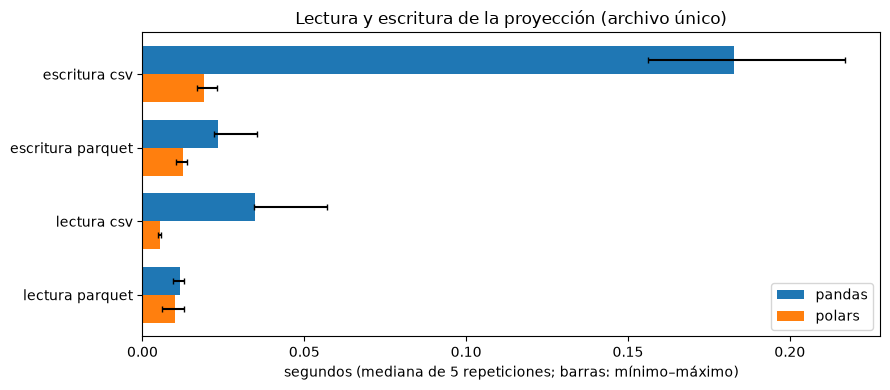

In [15]:
# 3.3 Resultados: ejecución inicial aparte, mediana/mínimo/máximo de las cinco repeticiones y tiempos individuales
tabla_med = pd.DataFrame(mediciones)
solo_es = tabla_med["operacion"].isin(["lectura", "escritura"])
inicial_es = tabla_med[(tabla_med["repeticion"] == 0) & solo_es]
rep_es = tabla_med[(tabla_med["repeticion"] > 0) & solo_es]
assert (rep_es.groupby(["operacion", "formato", "motor"]).size() == REPETICIONES).all()

print("Ejecución inicial (aparte; no entra en la mediana):")
display(inicial_es[["operacion", "formato", "motor", "segundos"]].reset_index(drop=True).round(5))

resumen_es = resumen_por_motor(rep_es, ["operacion", "formato"])
print("Mediana, mínimo y máximo de las cinco repeticiones (segundos):")
display(resumen_es.round(5))

print("Tiempos individuales de las cinco repeticiones (segundos):")
display(rep_es.pivot(index="repeticion", columns=["operacion", "formato", "motor"], values="segundos").round(5))

grafico_medianas(resumen_es, [f"{o} {f}" for o, f in zip(resumen_es["operacion"], resumen_es["formato"])],
                 "Lectura y escritura de la proyección (archivo único)")

**Interpretación (método y límites):**

- **Qué se midió.** Lectura completa de los mismos archivos CSV y Parquet con ambos motores, con las conversiones del contrato dentro del intervalo (tipos y nulos en CSV; `astype`/`cast` en Parquet). La escritura parte de los datos equivalentes ya cargados, con el mismo orden de columnas, separador, nulos y compresión Snappy. Se hizo una ejecución inicial aparte y cinco repeticiones que alternan el motor que corre primero; cada repetición escribe en una ruta nueva. La impresión, la validación y el inventario quedaron fuera del intervalo.
- **Opciones que no se pudieron igualar.** pandas escribe los booleanos como `True`/`False` y Polars como `true`/`false`; los dos se releen igual con el contrato común. Los dos motores usan su propio escritor de Parquet, con metadatos y organización interna distintos, así que los bytes no coinciden aunque ambos usen Snappy: la equivalencia se comprobó por relectura, no por tamaño.
- **Límites.** No se controló la caché del sistema, por eso las lecturas no se describen como «frías». Son cinco repeticiones sobre una sola máquina y un conjunto de este tamaño; con tiempos de milisegundos la variación entre repeticiones puede ser tan grande como la diferencia entre motores. Si el disco es de red o está montado desde otro sistema (por ejemplo `/mnt/c` en WSL), la escritura puede variar mucho más.

## 4. Procesamiento y consulta desde disco · 40 minutos

Separa dos experimentos:

1. **En memoria:** mide solo el filtro y la agregación sobre tablas ya cargadas en pandas y Polars.
2. **Desde disco:** mide hasta obtener el resultado del filtro y la agregación. Compara archivo único, archivos por año y archivos por año/departamento.

Para las partes, lee el inventario CSV dentro del intervalo medido, filtra sus claves con pandas y obtiene la lista de rutas. Para un año solo, selecciona sus partes y aplica el departamento sobre los registros leídos; para año/departamento, selecciona ambas claves. Usa exactamente la misma lista de archivos para los dos motores. Registra qué rutas seleccionaste. La tabla de inventario es pequeña y se usa igual en ambos recorridos.

En pandas, muestra un bucle que llame a `pd.read_parquet` para cada ruta y luego `pd.concat`. En Polars, muestra un bucle con `pl.read_parquet` y luego `pl.concat`. En cada caso, aplica las mismas condiciones analíticas y agregaciones. El ejemplo siguiente explica la lectura pandas; escribe su equivalente Polars:

```python
partes_pd = []
for ruta in rutas_seleccionadas:
    parte_pd = pd.read_parquet(
        ruta,
        engine="pyarrow",
        columns=["id_fila", "anio", "codigo_departamento",
                 "codigo_municipio", "ph", "ph_valido"]
    )
    partes_pd.append(parte_pd)
seleccion_pd = pd.concat(partes_pd, ignore_index=True)
```

Antes de medir, verifica que la consulta elegida tiene archivos candidatos. Si no los tiene, presenta un resultado vacío con esquema explícito; no llames `concat` sobre una lista vacía.

**Consulta diferida adicional:** sobre el Parquet único usa `pl.scan_parquet`, selección de columnas, filtro, agregación y `collect()`. Mide la ejecución completa y muestra `explain()` fuera del tiempo medido. Contrasta esta variante con `pl.read_parquet`; así separas el efecto de la consulta diferida del de dividir archivos.

**Control:** cinco repeticiones por variante, mismos datos y resultados materializados. Incluye lectura del inventario, selección de rutas, lectura de partes, concatenación, filtro y agregación en el experimento desde disco. Excluye impresión y comprobaciones. Los bytes de archivos seleccionados no son una medida de bytes físicos leídos. No compares construir un plan con ejecutarlo.

In [16]:
# 4.1 Funciones del experimento desde disco (todo el recorrido está a la vista) y verificación de archivos candidatos
RESULTADO_VACIO_PD = pd.DataFrame({"codigo_municipio": pd.Series(dtype="string"),
                                   "total_analisis": pd.Series(dtype="int64"),
                                   "ph_validos": pd.Series(dtype="Int64"),
                                   "media_ph": pd.Series(dtype="float64")})
RESULTADO_VACIO_PL = pl.DataFrame(schema={"codigo_municipio": pl.String, "total_analisis": pl.UInt32,
                                          "ph_validos": pl.UInt32, "media_ph": pl.Float64})
VARIANTES = ["unico", "por_anio", "por_anio_departamento"]
INVENTARIO_DE = {"por_anio": "inventario_anio.csv", "por_anio_departamento": "inventario_anio_departamento.csv"}

def rutas_candidatas(variante, anio, departamento):
    """Lee el inventario CSV, filtra sus claves con pandas y devuelve la lista de rutas (la misma para ambos motores)."""
    if variante == "unico":
        return [str(RUTAS["parquet"])]
    inventario = leer_inventario(EJECUCION_A, INVENTARIO_DE[variante])
    seleccion = mascara_igual(inventario["anio"], anio)      # por año: el departamento se filtra después, sobre los registros leídos
    if variante == "por_anio_departamento":
        seleccion = seleccion & mascara_igual(inventario["codigo_departamento"], departamento)
    return [str(EJECUCION_A / ruta) for ruta in inventario.loc[seleccion, "archivo"]]

def consulta_disco_pd(rutas, anio, departamento):
    """pandas: bucle de read_parquet por ruta, concat, filtro y agregación. Con cero rutas devuelve un resultado vacío."""
    if not rutas:
        return RESULTADO_VACIO_PD.copy(), 0              # no se llama concat sobre una lista vacía
    partes_pd = []
    for ruta in rutas:
        parte_pd = pd.read_parquet(ruta, engine="pyarrow", columns=COLUMNAS)
        partes_pd.append(parte_pd)
    seleccion_pd = pd.concat(partes_pd, ignore_index=True)
    return consulta_pd(seleccion_pd, anio, departamento), len(seleccion_pd)

def consulta_disco_pl(rutas, anio, departamento):
    """Polars: bucle de read_parquet por ruta, concat, filtro y agregación. Con cero rutas devuelve un resultado vacío."""
    if not rutas:
        return RESULTADO_VACIO_PL.clone(), 0
    partes_pl = []
    for ruta in rutas:
        parte_pl = pl.read_parquet(ruta, columns=COLUMNAS)
        partes_pl.append(parte_pl)
    seleccion_pl = pl.concat(partes_pl)
    return consulta_pl(seleccion_pl, anio, departamento), seleccion_pl.height

# Antes de medir: la consulta elegida debe tener archivos candidatos
filas_candidatas = {
    "unico": N,
    "por_anio": int(inv_anio.loc[mascara_igual(inv_anio["anio"], ANIO), "filas"].sum()),
    "por_anio_departamento": int(inv_anio_depto.loc[mascara_igual(inv_anio_depto["anio"], ANIO)
                                 & mascara_igual(inv_anio_depto["codigo_departamento"], DEPARTAMENTO), "filas"].sum()),
}
filas_tabla = []
for variante in VARIANTES:
    rutas = rutas_candidatas(variante, ANIO, DEPARTAMENTO)
    assert rutas, f"La consulta no tiene archivos candidatos en {variante}"
    filas_tabla.append({"diseño": variante, "archivos seleccionados": len(rutas),
                        "rutas": [str(Path(r).relative_to(EJECUCION_A)) for r in rutas],
                        "filas en esos archivos": filas_candidatas[variante],
                        "bytes de esos archivos (no son bytes físicos leídos)": sum(os.path.getsize(r) for r in rutas)})
display(pd.DataFrame(filas_tabla))

# Caso sin archivos candidatos: resultado vacío con esquema explícito en ambos motores
ANIO_AUSENTE = int(proyeccion_pd["anio"].min()) - 1
for variante in ["por_anio", "por_anio_departamento"]:
    rutas_vacias = rutas_candidatas(variante, ANIO_AUSENTE, DEPARTAMENTO)
    vacio_pd, leidas_pd = consulta_disco_pd(rutas_vacias, ANIO_AUSENTE, DEPARTAMENTO)
    vacio_pl, leidas_pl = consulta_disco_pl(rutas_vacias, ANIO_AUSENTE, DEPARTAMENTO)
    print(f"{variante}, año {ANIO_AUSENTE}: {len(rutas_vacias)} archivos candidatos | filas leídas {leidas_pd}/{leidas_pl} | "
          f"filas del resultado {len(vacio_pd)}/{vacio_pl.height}")
    assert len(rutas_vacias) == 0 and len(vacio_pd) == 0 and vacio_pl.height == 0
esquema_vacio = pd.DataFrame({"pandas": vacio_pd.dtypes.astype(str),
                              "Polars": pd.Series({c: str(t) for c, t in vacio_pl.schema.items()})})
print("Esquema explícito del resultado vacío:")
display(esquema_vacio)
anotar("4", "sin archivos candidatos: resultado vacío con esquema, sin concat de lista vacía", True)

,diseño,archivos seleccionados,rutas,filas en esos archivos,bytes de esos archivos (no son bytes físicos leídos)
0,unico,1,[unico.parquet],92738,830521
1,por_anio,1,[por_anio/parte-0000.parquet],10886,96684
2,por_anio_departamento,1,[por_anio_departamento/parte-0025.parquet],93,4811


por_anio, año 2013: 0 archivos candidatos | filas leídas 0/0 | filas del resultado 0/0
por_anio_departamento, año 2013: 0 archivos candidatos | filas leídas 0/0 | filas del resultado 0/0
Esquema explícito del resultado vacío:


,pandas,Polars
codigo_municipio,string,String
total_analisis,int64,UInt32
ph_validos,Int64,UInt32
media_ph,float64,Float64


True

In [17]:
# 4.2 Dos experimentos, cinco repeticiones más una ejecución inicial, alternando el orden de motores.
#     (a) En memoria: solo filtro + agregación sobre las tablas ya cargadas.
#     (b) Desde disco: inventario, selección de rutas, lectura de partes, concat, filtro y agregación.
resultados_guardados = []     # (diseño, motor, repetición, resultado): se comprueban fuera del reloj
rutas_usadas = {}

for rep in range(REPETICIONES + 1):
    for motor in (["pandas", "polars"] if rep % 2 == 0 else ["polars", "pandas"]):
        # ---- (a) en memoria ----
        if motor == "pandas":
            t0 = time.perf_counter()
            res = consulta_pd(proyeccion_pd, ANIO, DEPARTAMENTO)
            t = time.perf_counter() - t0
        else:
            t0 = time.perf_counter()
            res = consulta_pl(proyeccion_pl, ANIO, DEPARTAMENTO)
            t = time.perf_counter() - t0
        registrar(motor, "consulta_memoria", "memoria", "ninguno", rep, t, N, len(res))
        resultados_guardados.append(("memoria", motor, rep, res))

        # ---- (b) desde disco: archivo único, por año y por año/departamento ----
        for variante in VARIANTES:
            t0 = time.perf_counter()
            rutas = rutas_candidatas(variante, ANIO, DEPARTAMENTO)       # incluye leer el inventario
            if motor == "pandas":
                res, filas_leidas = consulta_disco_pd(rutas, ANIO, DEPARTAMENTO)
            else:
                res, filas_leidas = consulta_disco_pl(rutas, ANIO, DEPARTAMENTO)
            t = time.perf_counter() - t0
            registrar(motor, "consulta_disco", "parquet", variante, rep, t, filas_leidas, len(res))
            rutas_usadas[(variante, motor)] = rutas
            resultados_guardados.append((variante, motor, rep, res))

# ---- (c) Consulta diferida frente a lectura inmediata, ambas sobre el Parquet único ----
#      Se mide la ejecución completa (collect incluido); explain() va fuera del intervalo.
for rep in range(REPETICIONES + 1):
    for modo in (["inmediata", "diferida"] if rep % 2 == 0 else ["diferida", "inmediata"]):
        if modo == "inmediata":
            t0 = time.perf_counter()
            res = consulta_pl(pl.read_parquet(RUTAS["parquet"], columns=COLUMNAS), ANIO, DEPARTAMENTO)
            t = time.perf_counter() - t0
        else:
            t0 = time.perf_counter()
            res = consulta_pl(pl.scan_parquet(RUTAS["parquet"]).select(COLUMNAS), ANIO, DEPARTAMENTO).collect()
            t = time.perf_counter() - t0
        registrar("polars", f"consulta_{modo}", "parquet", "unico", rep, t, N, len(res))
        resultados_guardados.append((f"{modo}", "polars", rep, res))

print("Plan de la consulta diferida (fuera del tiempo medido):")
print(consulta_pl(pl.scan_parquet(RUTAS["parquet"]).select(COLUMNAS), ANIO, DEPARTAMENTO).explain())
print("Mediciones registradas hasta ahora:", len(mediciones))

Plan de la consulta diferida (fuera del tiempo medido):
AGGREGATE[maintain_order: false]
  [len().alias("total_analisis"), col("ph_valido").sum().alias("ph_validos"), col("ph").filter(col("ph_valido")).mean().alias("media_ph")] BY [col("codigo_municipio")]
  FROM
  Parquet SCAN [/opt/bigdata/big-data-postgraduate/kit/salidas/soluciones/PD05/ejecucion_A_20261113_170654_148530/unico.parquet]
  PROJECT 5/6 COLUMNS
  SELECTION: [([(col("anio")) == (2014)]) & ([(col("codigo_departamento")) == ("85")])]
  ESTIMATED ROWS: 92738
Mediciones registradas hasta ahora: 108


Resultados materializados comparados con la referencia de la actividad 1 (todas las repeticiones):


,diseño,motor,resultados,equivalentes
0,diferida,polars,6,6
1,inmediata,polars,6,6
2,memoria,pandas,6,6
3,memoria,polars,6,6
4,por_anio,pandas,6,6
5,por_anio,polars,6,6
6,por_anio_departamento,pandas,6,6
7,por_anio_departamento,polars,6,6
8,unico,pandas,6,6
9,unico,polars,6,6


Ejecución inicial (aparte; no entra en la mediana):


,operacion,particionamiento,motor,segundos
0,consulta_memoria,ninguno,pandas,0.01989
1,consulta_disco,unico,pandas,0.02659
2,consulta_disco,por_anio,pandas,0.02042
3,consulta_disco,por_anio_departamento,pandas,0.01647
4,consulta_memoria,ninguno,polars,0.00745
5,consulta_disco,unico,polars,0.01267
6,consulta_disco,por_anio,polars,0.01240
7,consulta_disco,por_anio_departamento,polars,0.01252
8,consulta_inmediata,unico,polars,0.00521
9,consulta_diferida,unico,polars,0.02459


(a) En memoria: solo filtro + agregación (segundos):


,operacion,mediana_pandas,mediana_polars,minimo_pandas,minimo_polars,maximo_pandas,maximo_polars,pandas / Polars (medianas),rangos solapados
0,consulta_memoria,0.00968,0.00429,0.00903,0.00295,0.01165,0.00599,2.25521,False


... (2 outputs left out)

(c) Consulta diferida frente a lectura inmediata, ambas en Polars sobre el Parquet único (segundos):


,mediana,minimo,maximo
operacion,,,
consulta_diferida,0.00842,0.00445,0.00931
consulta_inmediata,0.00885,0.00489,0.01336


Tiempos individuales de las cinco repeticiones (segundos):


operacion        consulta_memoria consulta_disco           \
particionamiento          ninguno          unico por_anio   
motor                      polars         polars   polars   
repeticion                                                  
1                         0.00599        0.01376  0.01113   
2                         0.00295        0.01530  0.00680   
3                         0.00429        0.00795  0.00884   
4                         0.00494        0.00875  0.00671   
5                         0.00387        0.00770  0.00762   

operacion                              consulta_memoria consulta_disco  \
particionamiento por_anio_departamento          ninguno          unico   
motor                           polars           pandas         pandas   
repeticion                                                               
1                              0.00911          0.00968        0.02007   
2                              0.01014          0.01007        0.01981   
3                              0.00640          0.00929        0.01783   
4                              0.00690          0.01165        0.02468   
5                              0.00705          0.00903        0.01583   

operacion                                       consulta_diferida  \
particionamiento por_anio por_anio_departamento             unico   
motor              pandas                pandas            polars   
repeticion                                                          
1                 0.02046               0.01449           0.00854   
2                 0.01623               0.01475           0.00842   
3                 0.01775               0.01818           0.00931   
4                 0.01741               0.01257           0.00445   
5                 0.01303               0.01387           0.00817   

operacion        consulta_inmediata  
particionamiento              unico  
motor                        polars  
repeticion                           
1                           0.01336  
2                           0.01135  
3                           0.00489  
4                           0.00621  
5                           0.00885

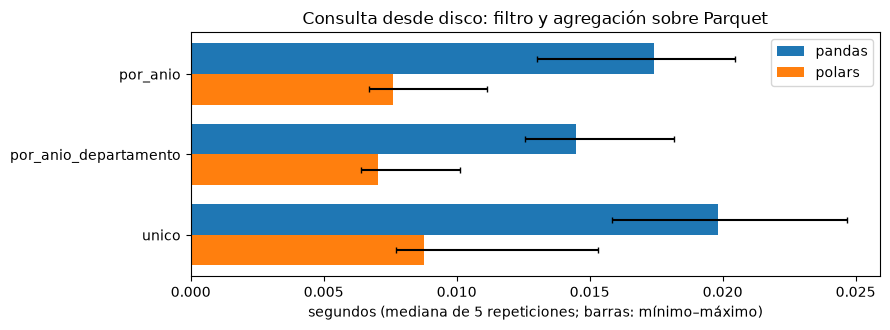

In [18]:
# 4.3 Controles fuera del reloj y resultados
for variante in VARIANTES:
    assert rutas_usadas[(variante, "pandas")] == rutas_usadas[(variante, "polars")], "los motores usaron rutas distintas"

verificacion = []
for diseno, motor, rep, res in resultados_guardados:
    verificacion.append({"diseño": diseno, "motor": motor, "repetición": rep, "ok": bool(comparar(resultado_pd, res)["ok"].all())})
verificacion = pd.DataFrame(verificacion)
print("Resultados materializados comparados con la referencia de la actividad 1 (todas las repeticiones):")
display(verificacion.groupby(["diseño", "motor"])["ok"].agg(resultados="size", equivalentes="sum").reset_index())
assert verificacion["ok"].all(), "algún resultado no coincide con la referencia"
anotar("4", "todos los resultados (memoria, disco, diferida) = referencia", verificacion["ok"].all())
anotar("4", "ambos motores usaron la misma lista de rutas", True)

tabla_med = pd.DataFrame(mediciones)
es_consulta = tabla_med["operacion"].str.startswith("consulta")
inicial_q = tabla_med[(tabla_med["repeticion"] == 0) & es_consulta]
rep_q = tabla_med[(tabla_med["repeticion"] > 0) & es_consulta]
assert (rep_q.groupby(["operacion", "particionamiento", "motor"]).size() == REPETICIONES).all()

print("Ejecución inicial (aparte; no entra en la mediana):")
display(inicial_q[["operacion", "particionamiento", "motor", "segundos"]].reset_index(drop=True).round(5))

print("(a) En memoria: solo filtro + agregación (segundos):")
resumen_mem = resumen_por_motor(rep_q[rep_q["operacion"] == "consulta_memoria"], ["operacion"])
display(resumen_mem.round(5))

print("(b) Desde disco: inventario + selección + lectura + concat + filtro + agregación (segundos):")
resumen_disco = resumen_por_motor(rep_q[rep_q["operacion"] == "consulta_disco"], ["particionamiento"])
filas_leidas_tabla = (rep_q[rep_q["operacion"] == "consulta_disco"]
                      .groupby("particionamiento")["filas_entrada"].first().rename("filas leídas"))
display(resumen_disco.merge(filas_leidas_tabla, on="particionamiento").round(5))

print("(c) Consulta diferida frente a lectura inmediata, ambas en Polars sobre el Parquet único (segundos):")
resumen_lazy = (rep_q[rep_q["operacion"].isin(["consulta_inmediata", "consulta_diferida"])]
                .groupby("operacion")["segundos"].agg(mediana="median", minimo="min", maximo="max"))
display(resumen_lazy.round(5))

print("Tiempos individuales de las cinco repeticiones (segundos):")
display(rep_q.pivot(index="repeticion", columns=["operacion", "particionamiento", "motor"], values="segundos").round(5))

grafico_medianas(resumen_disco, resumen_disco["particionamiento"].tolist(),
                 "Consulta desde disco: filtro y agregación sobre Parquet")

**Interpretación:**

Cuando el dataset se particiona manualmente por año y departamento, el filtrado previo sobre el archivo de inventario permite una poda de particiones (partition pruning) efectiva, evitando abrir la inmensa mayoría de los datos. Por otro lado, al trabajar sobre el archivo Parquet único mediante la API Lazy (pl.scan_parquet), Polars aplica automáticamente projection pushdown (lee solo las 6 columnas solicitadas) y predicate pushdown (filtra grupos de filas directamente usando las estadísticas internas del formato Parquet).

## 5. Llevar los resultados tabulares a un mapa · 30 minutos

Lee directamente la capa `municipios` del GeoPackage de PD04. Muestra columnas, CRS y cantidad de geometrías. Selecciona únicamente código y geometría para evitar reutilizar por accidente los indicadores del año anterior.

Convierte el resultado agregado de Polars con `.to_pandas()` después de medir. Une por separado el resultado pandas y el resultado Polars con los mismos polígonos mediante `merge(..., how="left", validate="one_to_one")`. Conserva el código como texto y verifica antes la unicidad. Presenta resultados sin geometría y polígonos sin resultado.

Genera dos mapas del departamento y año elegidos, uno por motor, usando igual extensión, columna, límites de color, leyenda y tratamiento de ausentes. Guarda `comparacion_mapas.png`. Comprueba numéricamente las claves, conteos y medias antes de juzgar la igualdad visual.

**Control:** las geometrías no participan en el benchmark tabular ni se convierten a texto para medirlas con Polars. La unión y la representación son trabajo de GeoPandas fuera de esos tiempos. Un mapa igual no sustituye una comparación de valores. La cantidad de registros no demuestra cobertura completa de suelos.

In [19]:
geometrias = gpd.read_file(
    REPO + "/kit/salidas/soluciones/PD04/resultados_espaciales.gpkg",
    layer="municipios",
    engine="pyogrio"
)
display(geometrias.head())
print(geometrias.shape, geometrias.crs)

,dpto_ccdgo,mpio_ccdgo,mpio_cdpmp,dpto_cnmbr,mpio_cnmbr,mpio_crslc,mpio_tipo,mpio_narea,mpio_nano,shape_Leng,shape_Area,codigo_municipio,total_analisis_2016,ph_validos_2016,ph_media_2016,_merge,area_ha,area_intersectada_ha,n_piezas,geometry
0,05,001,05001,ANTIOQUIA,MEDELLÍN,1965,MUNICIPIO,374.741484,2025,1.035380,0.030608,05001,1.0,1.0,5.650000,both,37474.148450,0.0,0,"MULTIPOLYGON (((-75.4857 6.20163, -75.48567 6...."
1,05,002,05002,ANTIOQUIA,ABEJORRAL,1814,MUNICIPIO,506.959782,2024,1.158504,0.041384,05002,2.0,2.0,6.740000,both,50695.978227,0.0,0,"MULTIPOLYGON (((-75.46938 5.94575, -75.46897 5..."
2,05,004,05004,ANTIOQUIA,ABRIAQUÍ,1912,MUNICIPIO,296.974188,2025,0.810667,0.024253,05004,NaN,NaN,NaN,left_only,29697.418845,0.0,0,"MULTIPOLYGON (((-76.09047 6.74542, -76.09066 6..."
3,05,021,05021,ANTIOQUIA,ALEJANDRÍA,Decreto departamental 304 de 1907,MUNICIPIO,128.856431,2024,0.705200,0.010535,05021,NaN,NaN,NaN,left_only,12885.643129,0.0,0,"MULTIPOLYGON (((-75.0332 6.41586, -75.03313 6...."
4,05,030,05030,ANTIOQUIA,AMAGÁ,1912,MUNICIPIO,84.117145,2024,0.445533,0.006867,05030,17.0,17.0,5.158824,both,8411.714470,0.0,0,"MULTIPOLYGON (((-75.67587 6.08561, -75.6754 6...."


(1122, 20) EPSG:4326


Capa municipios: 1122 geometrías | CRS: EPSG:4326 | vacías: 0
Columnas de la capa: ['dpto_ccdgo', 'mpio_ccdgo', 'mpio_cdpmp', 'dpto_cnmbr', 'mpio_cnmbr', 'mpio_crslc', 'mpio_tipo', 'mpio_narea', 'mpio_nano', 'shape_Leng', 'shape_Area', 'codigo_municipio', 'total_analisis_2016', 'ph_validos_2016', 'ph_media_2016', '_merge', 'area_ha', 'area_intersectada_ha', 'n_piezas', 'geometry']
¿codigo_municipio coincide con el código DANE mpio_cdpmp en todos los polígonos? True


,control,detalle,ok
0,mismo número de grupos,11 y 11,True
1,claves iguales (el nulo cuenta como clave),,True
2,claves nulas en la misma posición,,True
3,total_analisis exacto,,True
4,ph_validos exacto,,True
5,medias ausentes en la misma posición,,True
6,media_ph con atol=1e-6 y rtol=0,diferencia máxima = 0.00e+00,True


,tabla,claves,claves únicas
0,polígonos,1122,True
1,resultado pandas,11,True
2,resultado Polars,11,True


,conteo
polígonos en la capa,1122
polígonos del departamento 85,19
· con resultado y media de pH,10
· con análisis pero sin pH válido (media ausente),1
· sin resultado (no hay análisis ese año),8
resultados sin geometría,0


Polígonos del departamento sin resultado: ['85015', '85125', '85136', '85250', '85279', '85300', '85315', '85400']
Resultados sin geometría:


,codigo_municipio,total_analisis,ph_validos,media_ph


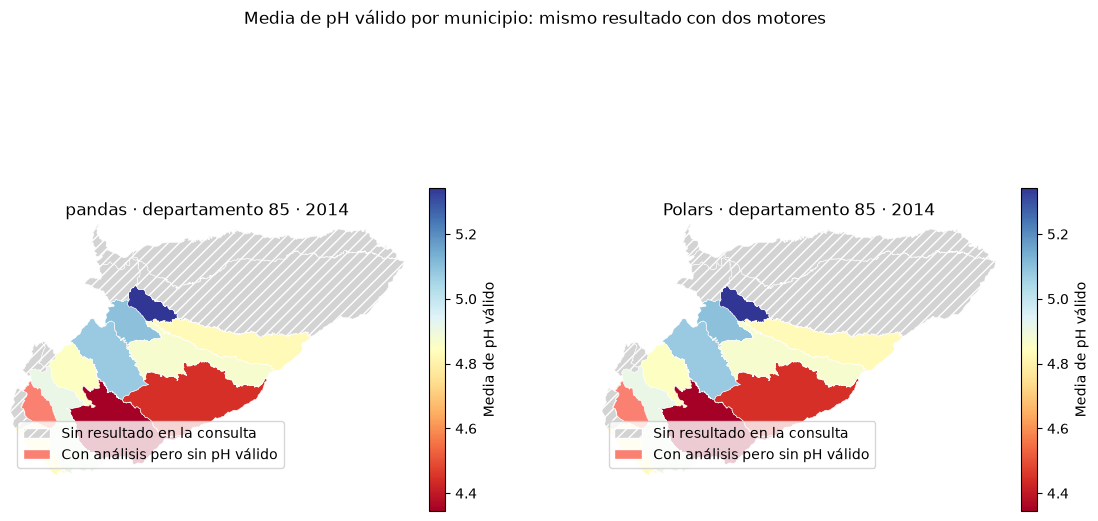

Mapa guardado en: /opt/bigdata/big-data-postgraduate/kit/salidas/soluciones/PD05/comparacion_mapas.png


In [20]:
# 5.1 Solo código y geometría: no se reutilizan los indicadores del año anterior que trae la capa
from matplotlib.patches import Patch

GEOM = geometrias.geometry.name
poligonos = geometrias[["codigo_municipio", GEOM]].copy()
poligonos["codigo_municipio"] = poligonos["codigo_municipio"].astype("string")
print("Capa municipios:", geometrias.shape[0], "geometrías | CRS:", geometrias.crs,
      "| vacías:", int(poligonos.geometry.is_empty.sum()))
print("Columnas de la capa:", geometrias.columns.tolist())
if "mpio_cdpmp" in geometrias.columns:
    coincide_dane = (geometrias["codigo_municipio"].astype("string") == geometrias["mpio_cdpmp"].astype("string")).all()
    print("¿codigo_municipio coincide con el código DANE mpio_cdpmp en todos los polígonos?",
          anotar("5", "codigo_municipio = mpio_cdpmp en la capa", coincide_dane))

# 5.2 Resultado agregado: el de Polars se convierte con .to_pandas() DESPUÉS de medir
def normalizar_resultado(res):
    """Mismo esquema para el resultado de pandas y el de Polars."""
    return como_pandas(res).astype({"codigo_municipio": "string", "total_analisis": "Int64",
                                    "ph_validos": "Int64", "media_ph": "float64"})

res_pd_mapa = normalizar_resultado(resultado_pd)
res_pl_mapa = normalizar_resultado(resultado_pl.to_pandas())

controles_tabla = comparar(res_pd_mapa, res_pl_mapa)      # primero los valores; luego los mapas
display(controles_tabla)
assert controles_tabla["ok"].all()

unicidad = pd.DataFrame([
    {"tabla": "polígonos", "claves": len(poligonos), "claves únicas": bool(poligonos["codigo_municipio"].is_unique)},
    {"tabla": "resultado pandas", "claves": res_pd_mapa["codigo_municipio"].notna().sum(), "claves únicas": bool(res_pd_mapa["codigo_municipio"].dropna().is_unique)},
    {"tabla": "resultado Polars", "claves": res_pl_mapa["codigo_municipio"].notna().sum(), "claves únicas": bool(res_pl_mapa["codigo_municipio"].dropna().is_unique)},
])
display(unicidad)
assert unicidad["claves únicas"].all()

# 5.3 Unión por separado, mismos polígonos, validate="one_to_one" (las claves nulas no se unen: se reportan aparte)
mapa_pd = poligonos.merge(res_pd_mapa.dropna(subset=["codigo_municipio"]), on="codigo_municipio",
                          how="left", validate="one_to_one")
mapa_pl = poligonos.merge(res_pl_mapa.dropna(subset=["codigo_municipio"]), on="codigo_municipio",
                          how="left", validate="one_to_one")
pd.testing.assert_frame_equal(mapa_pd.drop(columns=GEOM), mapa_pl.drop(columns=GEOM),
                              check_exact=False, atol=1e-6, rtol=0)
anotar("5", "tablas unidas pandas = Polars (claves, conteos, medias)", True)

sin_geometria = res_pd_mapa[~res_pd_mapa["codigo_municipio"].isin(poligonos["codigo_municipio"])]
en_depto = mapa_pd["codigo_municipio"].str.startswith(DEPARTAMENTO)
depto_pd, depto_pl = mapa_pd[en_depto], mapa_pl[en_depto]
sin_resultado = depto_pd.loc[depto_pd["total_analisis"].isna(), "codigo_municipio"]
sin_ph = depto_pd.loc[depto_pd["total_analisis"].notna() & depto_pd["media_ph"].isna(), "codigo_municipio"]
resumen_union = pd.DataFrame({"conteo": {
    "polígonos en la capa": len(poligonos),
    f"polígonos del departamento {DEPARTAMENTO}": len(depto_pd),
    "  · con resultado y media de pH": int(depto_pd["media_ph"].notna().sum()),
    "  · con análisis pero sin pH válido (media ausente)": len(sin_ph),
    "  · sin resultado (no hay análisis ese año)": len(sin_resultado),
    "resultados sin geometría": len(sin_geometria)}})
display(resumen_union)
print("Polígonos del departamento sin resultado:", sin_resultado.tolist())
print("Resultados sin geometría:")
display(sin_geometria)

# 5.4 Dos mapas con la misma extensión, columna, escala, leyenda y tratamiento de ausentes
valores = depto_pd["media_ph"].dropna()
vmin, vmax = (float(valores.min()), float(valores.max())) if len(valores) else (0.0, 1.0)
if vmin == vmax:
    vmin, vmax = vmin - 0.5, vmax + 0.5
minx, miny, maxx, maxy = depto_pd.total_bounds
fig, ejes = plt.subplots(1, 2, figsize=(14, 7), sharex=True, sharey=True)
for eje, datos, motor in [(ejes[0], depto_pd, "pandas"), (ejes[1], depto_pl, "Polars")]:
    datos.plot(column="media_ph", ax=eje, cmap="RdYlBu", vmin=vmin, vmax=vmax, edgecolor="white", linewidth=0.4,
               legend=True, legend_kwds={"label": "Media de pH válido", "shrink": 0.6},
               missing_kwds={"color": "lightgrey", "edgecolor": "white", "hatch": "///"})
    if len(sin_ph):
        datos[datos["codigo_municipio"].isin(sin_ph)].plot(ax=eje, color="salmon", edgecolor="white", linewidth=0.4)
    eje.set_xlim(minx, maxx)
    eje.set_ylim(miny, maxy)
    eje.set_title(f"{motor} · departamento {DEPARTAMENTO} · {ANIO}")
    eje.set_axis_off()
    eje.legend(handles=[Patch(facecolor="lightgrey", hatch="///", edgecolor="white", label="Sin resultado en la consulta"),
                        Patch(facecolor="salmon", edgecolor="white", label="Con análisis pero sin pH válido")],
               loc="lower left")
fig.suptitle("Media de pH válido por municipio: mismo resultado con dos motores")
fig.savefig(Path(OUT) / "comparacion_mapas.png", dpi=150, bbox_inches="tight")
plt.show()
print("Mapa guardado en:", Path(OUT) / "comparacion_mapas.png")

**Interpretación (método y límites):**

- **Qué se hizo.** De la capa `municipios` solo se tomaron el código y la geometría, para no mezclar los indicadores que PD04 dejó guardados en ella. El resultado de Polars se convirtió con `.to_pandas()` después de medir, y cada resultado (pandas y Polars) se unió por separado a los mismos polígonos con `how="left"` y `validate="one_to_one"`, con el código como texto y la unicidad comprobada antes.
- **Orden de los controles.** Primero se compararon numéricamente claves, conteos y medias, y las tablas unidas; después se dibujaron los mapas. Los dos mapas comparten extensión, columna, límites de color, leyenda y tratamiento de ausentes. Un mapa igual no sustituye la comparación de valores: la igualdad la demuestran los controles, no la imagen.
- **Ausentes.** Se distinguen dos casos que en un mapa se confunden: un polígono sin resultado (no hay análisis ese año) y uno con análisis pero sin ningún pH válido (media ausente). Un municipio sin resultado no tiene cero análisis: simplemente no hay muestras en la fuente.
- **Límites.** Las geometrías no participan en el benchmark tabular ni se convierten a texto. La cantidad de registros no demuestra cobertura completa de suelos, y la media de pH de municipios con pocos análisis es poco estable.

## 6. Reejecución, evidencia y decisión · 45 minutos

Repite la construcción de los archivos en otra carpeta de ejecución nueva. No borres carpetas de datos originales ni reutilices un directorio particionado con archivos viejos. Comprueba contenido y total de registros; el nombre de los archivos o su hash no tiene por qué coincidir para que el contenido sea equivalente.

Guarda `mediciones.csv` con motor, versión, operación, formato, particionamiento, repetición, segundos, filas de entrada y filas de salida. Guarda aparte la ejecución inicial; calcula la mediana solo con las cinco repeticiones medidas. Añade inventario de bytes/archivos y controles de equivalencia.

Responde: ¿qué parte mejora con Parquet?, ¿cuándo ayuda la selección de particiones?, ¿qué diseño genera archivos demasiado pequeños?, ¿qué cambia entre tiempo en memoria y tiempo desde disco?, ¿qué elegirías para este conjunto y por qué?

**Control:** no presupongas que Polars o el particionamiento ganarán. Diferencias pequeñas o variables deben describirse como tales. El tamaño de un DataFrame no equivale a la memoria máxima del proceso.

In [21]:
# 6.1 Segunda construcción en una carpeta de ejecución nueva (no se borra ni se reutiliza la primera)
EJECUCION_B = nueva_ejecucion("ejecucion_B")
repr_B = construir_representaciones(EJECUCION_B, proyeccion_pd)

conciliacion = []
for diseno, nombre_inventario in DISENOS:
    inv_a, rel_a = releer_particiones(EJECUCION_A, nombre_inventario)
    inv_b, rel_b = releer_particiones(EJECUCION_B, nombre_inventario)
    pd.testing.assert_frame_equal(rel_a, rel_b)                       # el contenido coincide, no necesariamente los bytes
    assert len(rel_b) == N and rel_b["id_fila"].is_unique
    conciliacion.append({"diseño": diseno, "archivos A": len(inv_a), "archivos B": len(inv_b),
                         "filas A": len(rel_a), "filas B": len(rel_b),
                         "bytes A": int(inv_a["bytes"].sum()), "bytes B": int(inv_b["bytes"].sum()),
                         "contenido A = B": True})
    anotar("6", f"{diseno}: ejecución B = ejecución A", True)
for formato in ["csv", "parquet"]:
    a = leer_pd(RUTAS[formato], formato).sort_values("id_fila", ignore_index=True)
    b = leer_pd(repr_B[formato], formato).sort_values("id_fila", ignore_index=True)
    pd.testing.assert_frame_equal(a, b)
    conciliacion.append({"diseño": f"{formato} único", "archivos A": 1, "archivos B": 1, "filas A": len(a), "filas B": len(b),
                         "bytes A": RUTAS[formato].stat().st_size, "bytes B": repr_B[formato].stat().st_size,
                         "contenido A = B": True})
    anotar("6", f"{formato} único: ejecución B = ejecución A", True)
conciliacion = pd.DataFrame(conciliacion)
conciliacion["bytes iguales"] = conciliacion["bytes A"] == conciliacion["bytes B"]
display(conciliacion)

,diseño,archivos A,archivos B,filas A,filas B,bytes A,bytes B,contenido A = B,bytes iguales
0,por_anio,12,12,92738,92738,865004,865004,True,True
1,por_anio_departamento,373,373,92738,92738,2255366,2255366,True,True
2,csv único,1,1,92738,92738,2749328,2749328,True,True
3,parquet único,1,1,92738,92738,830521,830521,True,True


In [22]:
# 6.2 Evidencia: mediciones, ejecución inicial aparte, medianas solo con las cinco repeticiones, inventario y controles
COLS_MED = ["motor", "version", "operacion", "formato", "particionamiento", "repeticion", "segundos",
            "filas_entrada", "filas_salida"]
CLAVES_MED = ["operacion", "formato", "particionamiento", "motor"]
tabla_med = pd.DataFrame(mediciones)
med_rep = tabla_med[tabla_med["repeticion"] > 0]
med_ini = tabla_med[tabla_med["repeticion"] == 0]
assert (med_rep.groupby(CLAVES_MED).size() == REPETICIONES).all(), "cada variante debe tener 5 repeticiones"

med_rep[COLS_MED].to_csv(Path(OUT) / "mediciones.csv", index=False)
med_ini[COLS_MED].to_csv(Path(OUT) / "mediciones_iniciales.csv", index=False)
medianas = med_rep.groupby(CLAVES_MED)["segundos"].agg(mediana="median", minimo="min", maximo="max").reset_index()
medianas.to_csv(Path(OUT) / "medianas.csv", index=False)

inventario_bytes = pd.concat([
    pd.DataFrame({"ejecucion": nombre, "diseno": conciliacion["diseño"],
                  "archivos": conciliacion[f"archivos {letra}"], "bytes": conciliacion[f"bytes {letra}"]})
    for nombre, letra in [("A", "A"), ("B", "B")]], ignore_index=True)
inventario_bytes.to_csv(Path(OUT) / "inventario_bytes_archivos.csv", index=False)
entorno.to_csv(Path(OUT) / "entorno.csv")

anotar("6", "cada variante tiene 5 repeticiones medidas y su ejecución inicial aparte", True)
controles = pd.DataFrame(controles_equivalencia)
controles.to_csv(Path(OUT) / "controles_equivalencia.csv", index=False)

print(f"Mediciones: {len(med_rep)} repeticiones en mediciones.csv + {len(med_ini)} ejecuciones iniciales en mediciones_iniciales.csv")
print("Medianas (segundos) de las cinco repeticiones:")
display(medianas.pivot_table(index=["operacion", "formato", "particionamiento"], columns="motor", values="mediana").round(5))
print("Inventario de bytes y archivos (primera y segunda ejecución):")
display(inventario_bytes)
print("Controles de equivalencia:")
display(controles)
assert controles["resultado"].all(), "falló algún control de equivalencia"
print("Archivos de evidencia en", OUT, ":", sorted(p.name for p in Path(OUT).glob("*.*")))

Mediciones: 90 repeticiones en mediciones.csv + 18 ejecuciones iniciales en mediciones_iniciales.csv
Medianas (segundos) de las cinco repeticiones:


motor                                              pandas   polars
operacion          formato particionamiento                       
consulta_diferida  parquet unico                      NaN  0.00842
consulta_disco     parquet por_anio               0.01741  0.00762
                           por_anio_departamento  0.01449  0.00705
                           unico                  0.01981  0.00875
consulta_inmediata parquet unico                      NaN  0.00885
consulta_memoria   memoria ninguno                0.00968  0.00429
escritura          csv     unico                  0.18287  0.01908
                   parquet unico                  0.02327  0.01258
lectura            csv     unico                  0.03476  0.00552
                   parquet unico                  0.01151  0.01001

Inventario de bytes y archivos (primera y segunda ejecución):


,ejecucion,diseno,archivos,bytes
0,A,por_anio,12,865004
1,A,por_anio_departamento,373,2255366
2,A,csv único,1,2749328
3,A,parquet único,1,830521
4,B,por_anio,12,865004
5,B,por_anio_departamento,373,2255366
6,B,csv único,1,2749328
7,B,parquet único,1,830521


Controles de equivalencia:


,actividad,control,resultado
0,1,nulos por columna iguales en pandas y Polars,True
1,1,códigos de departamento con ceros iniciales ig...,True
2,1,"consulta pandas = consulta Polars (claves, con...",True
3,1,grupo de municipio nulo: mismas filas en panda...,True
4,1,dropna=False y group_by de Polars conservan to...,True
5,2,"por_anio: relectura = proyección, IDs únicos y...",True
6,2,"por_anio_departamento: relectura = proyección,...",True
7,2,CSV único y Parquet único releídos = proyección,True
8,2,filas con departamento ausente conservadas en ...,True
9,3,lecturas y escrituras releídas = proyección,True


Archivos de evidencia en /opt/bigdata/big-data-postgraduate/kit/salidas/soluciones/PD05 : ['comparacion_mapas.png', 'controles_equivalencia.csv', 'entorno.csv', 'inventario_bytes_archivos.csv', 'medianas.csv', 'mediciones.csv', 'mediciones_iniciales.csv']


**Interpretación (método y límites):**

- **Evidencia.** La segunda construcción se hizo en una carpeta nueva y se concilió por contenido (mismas filas, IDs únicos, mismo total), no por nombre ni por hash. `mediciones.csv` reúne solo las cinco repeticiones de cada variante y `mediciones_iniciales.csv` guarda aparte la ejecución inicial; las medianas usan solo las repeticiones. Además se guardan las medianas con su rango, el inventario de bytes y archivos, el entorno y los controles de equivalencia.
- **Cómo leer las respuestas.** No se presupone que Polars ni el particionamiento ganen: cuando los rangos de las cinco repeticiones se solapan, la diferencia se describe como no concluyente. El tamaño de un DataFrame no equivale a la memoria máxima del proceso, que aquí no se midió.
- **Alcance.** Los resultados describen este equipo y estos datos (menos de 100 000 filas, una sola máquina, caché del sistema sin controlar). No se extrapolan a tablas mucho mayores, donde el balance entre leer menos datos y abrir más archivos podría cambiar.

## Entrega y referencias de API

`soluciones/PD05_particionamiento_pandas_polars.ipynb`, mediciones, inventarios, comparación cartográfica y controles regenerables en `kit/salidas/soluciones/PD05/`. Incluye una recomendación basada en resultados; no se califica obtener el menor tiempo.

- [pandas: escritura de archivos Parquet](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.to_parquet.html)
- [Polars: fuentes y ejecución diferida](https://docs.pola.rs/user-guide/lazy/sources_sinks/)
- [Polars: scan_parquet](https://docs.pola.rs/api/python/stable/reference/api/polars.scan_parquet.html)

Usa las versiones fijadas por el curso; si la documentación más reciente muestra una opción diferente, comprueba su disponibilidad antes de usarla.